# Parte I – Análise conceitual

# Questão 1 – Otimização não significa apenas “fazer menos contas”

Supondo que A e B rodam no mesmo computador. O programa B pode ter uma melhor localidade espacial que o A, como é o exemplo de casos de acesso de matrizes por colunas(pior localidade) e por linhas(melhor localidade), nesse caso talves os acessos realizados por A, mesmo que menores, tem uma localidade pior.

O programa A talves esteja carregando na cache dados, mas apenas usando um desses dados em cada operacao, precisando entao carregar novos dados para entao realizar suas outras operações.

A estrutura de dados de A pode ser menos otimizada que a de B,como nos casos em que fazer busca de acessos em uma lista gera um custo maior do que fazer em um set.

O programa A pode estar gerando um overhead ao chamar funções que o programa B nao chama

# FALTA EXEMPLO

# Questão 2 – Hierarquia de memória
a) Porque o acesso a RAM é mais demorado que o acesso aos caches Ls, que por sua vez são mais demorados que os acessos aos registradores.

b) Um cache miss ocorre quando o dado buscado nao esta no nivel acessado, forçando a CPU a buscar o dado em um nivel abaixo. Eg: buscar em L3 um dado que esta na RAM

c) Um cache hit ocorre quando o dado buscado esta no nivel consultado

d) Localidade Espacial: Os vizinhos dos dados acessados tem a chance de serem acessados.

Localidade Temporal: Os dados agora acessados tem a chance de serem acessados novamente em breve

e) O primeiro padrao de acesso faz uso sequencial, oq gera uma localidade espacial melhor, pois os dados estao carregados em sequencia e tabem uma localidade temporal melhor, pois como o acesso esta ocorrendo sequencialmente, o proximo dado sera acessado em seguida.
O segundo padrao tem um stride muito grande e por isso a memoria cache precisa ser constantemente atualizada, levando a muito mais cache miss

# Parte II – Otimização sequencial
# Questão 3 – Análise do código
resultado = []
inves de declarar uma lista vazia, fazer a alocação previa do espaço de memoria 

resultado.append(valor)
previsa realocar toda a memoria anterior mais o espaço para o append em cada execução, como o tamanho e o tipo de dado sao conhecidos, fazer a alocação previa é melhor

fazer 2*math.sqrt(x[i]) para diminuir o overhead

In [1]:
import math 
import numpy as np
from numba import njit

In [2]:
# Versao A 
@njit
def calcula_A(x):
    resultado = []

    for i in range(len(x)):
        valor = math.sqrt(x[i]) + math.sqrt(x[i])
        resultado.append(valor)

    return resultado

In [3]:
# Versao B 
@njit
def calcula_B(x):
    resultado = [0.0] * len(x)
    size = len(x)

    for i in range(size):
        valor = 2 * math.sqrt(x[i])
        resultado[i] = valor

    return resultado

In [4]:
# Versao C
@njit
def calcula_C(x):
    size = len(x)
    resultado = np.empty(size, dtype=np.float64)

    for i in range(size):
        valor = 2 * math.sqrt(x[i])
        resultado[i] = valor

    return resultado

In [5]:
from time import perf_counter
element_size = (10_000, 100_000, 1_000_000, 10_000_000)

def time_benchmark(f, *args):
    resultados = []
    execution_times = []
    for i in range(5):
        t0 = perf_counter()
        resultado = f(*args)
        execution_times.append(perf_counter() - t0)
        resultados.append(resultado)
    return resultados, execution_times

def metrics(execution_times):
    median = np.median(execution_times)
    max = np.max(execution_times)
    min = np.min(execution_times)
    mean = np.mean(execution_times)
    return median, max, min, mean

In [6]:
import csv

headers = ['f_name', 'size', 'median', 'max', 'min', 'mean']
data = []
resultados = []

for size in element_size:
    for f in (calcula_A, calcula_B, calcula_C):
        resultado, execution_times = time_benchmark(f, np.arange(size))
        md, mx, mn, avg = metrics(execution_times)
        
        data.append([f.__name__, size, md, mx, mn, avg])
        resultados.append(resultado)

with open('resultados.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(headers)
    writer.writerows(data)

In [7]:
import pandas as pd 
df = pd.read_csv('resultados.csv')
print(df)

       f_name      size    median       max       min      mean
0   calcula_A     10000  0.000263  0.312961  0.000234  0.062795
1   calcula_B     10000  0.000251  0.074558  0.000228  0.015114
2   calcula_C     10000  0.000008  0.114486  0.000006  0.022909
3   calcula_A    100000  0.002757  0.003037  0.002591  0.002750
4   calcula_B    100000  0.002810  0.002867  0.002630  0.002767
5   calcula_C    100000  0.000350  0.000367  0.000056  0.000297
6   calcula_A   1000000  0.026971  0.031404  0.025570  0.027806
7   calcula_B   1000000  0.026220  0.029548  0.025365  0.026668
8   calcula_C   1000000  0.003427  0.003540  0.000537  0.002858
9   calcula_A  10000000  0.250106  0.262094  0.243309  0.251521
10  calcula_B  10000000  0.239870  0.245617  0.239153  0.241323
11  calcula_C  10000000  0.028899  0.036256  0.028484  0.030476


In [8]:
reshaped = (
    df.pivot(index="size", columns="f_name", values="mean")
      .rename(columns={
          "calcula_A": "mean_A",
          "calcula_B": "mean_B",
          "calcula_C": "mean_C",
      })
      .reset_index()
)

print(reshaped)

f_name      size    mean_A    mean_B    mean_C
0          10000  0.062795  0.015114  0.022909
1         100000  0.002750  0.002767  0.000297
2        1000000  0.027806  0.026668  0.002858
3       10000000  0.251521  0.241323  0.030476


In [9]:
speed_df = pd.DataFrame({
    'speedA': reshaped['mean_A'] / reshaped['mean_A'],
    'speedB': reshaped['mean_A'] / reshaped['mean_B'],
    'speedC': reshaped['mean_A'] / reshaped['mean_C'],
})

speed_df.insert(0, 'size', reshaped['size'])
print(speed_df)

       size  speedA    speedB    speedC
0     10000     1.0  4.154803  2.741031
1    100000     1.0  0.993771  9.251479
2   1000000     1.0  1.042680  9.729709
3  10000000     1.0  1.042258  8.253044


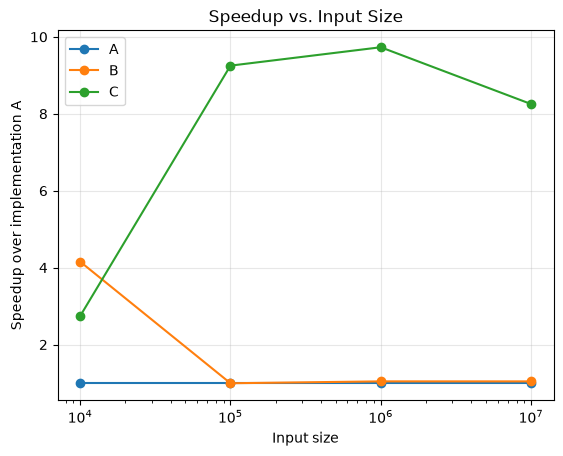

In [10]:
import matplotlib.pyplot as plt

# A is the baseline, so speedup = 1
#plt.axhline(y=1, linestyle="--", label="A", color='green')
plt.plot(speed_df["size"], speed_df["speedA"], marker="o", label="A")
plt.plot(speed_df["size"], speed_df["speedB"], marker="o", label="B")
plt.plot(speed_df["size"], speed_df["speedC"], marker="o", label="C")

plt.xscale("log")

plt.xlabel("Input size")
plt.ylabel("Speedup over implementation A")
plt.title("Speedup vs. Input Size")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Questao 5 - Speedup

a) A versao C (implementada em numpy) 
b) Somente para a versao B
c) Para C com base no aumento do numero de dados espera-se que exista uma demora maior de processamento quando os dados aumento na ordem de 10x a quantidade anterior o que explica o declinio visto no grafico entre 10e6 e 10e7. Agora o speed up tem um salto entre 10e4 e 105
d) a versao numpy utiliza uma estrutura de dados diferente, o que sobrescreve a maneira que operadores padrões funcionam, como o caso do [] de acesso, logo apesar do código ser semelhante visualmente, sua estrutura de funcionamento é diferente logicamente.


# Parte III – Cache e organização da memória

In [15]:
# Algoritmo 1 - percurso por linhas linhas
@njit
def sum_A(A, N):
    soma = 0.0
    for i in range(N):
        for j in range(N):
            soma += A[i, j]

# Algoritmo 2 - percurso por colunas
@njit
def sum_B(A, N):
    soma = 0.0
    for j in range(N):
        for i in range(N):
            soma += A[i, j]

# Q6 - Previsão antes do experimento 

o algoritmo 2 por conta da localidade espacial, onde os elementos sao carregados sequencialmente nas caches, ou seja, as linhas sao carregadas contiguamente na memoria entao o vizinho do elemento atual provavelmente ja esta carregado na memoria, enquanto q na implementacao A ha um risco maior de cache miss

In [16]:
N = (500, 1000, 2000, 3000, 4000)

headers = ['f_name', 'size', 'median', 'max', 'min', 'mean']
data = []
resultados = []

for size in N:
    A = np.random.random((size, size))
    for f in (sum_A, sum_B):
        resultado, execution_times = time_benchmark(f, A, size)
        md, mx, mn, avg = metrics(execution_times)
        
        data.append([f.__name__, size, md, mx, mn, avg])
        resultados.append(resultado)

with open('resultados_matrix.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(headers)
    writer.writerows(data)

In [17]:
df = pd.read_csv('resultados_matrix.csv')
print(df)

  f_name  size        median       max           min          mean
0  sum_A   500  2.800000e-07  0.000007  2.199999e-07  1.736000e-06
1  sum_B   500  2.690001e-07  0.000001  2.000002e-07  5.178000e-07
2  sum_A  1000  2.300001e-07  0.000005  2.200002e-07  1.152000e-06
3  sum_B  1000  2.899999e-07  0.000001  2.200002e-07  4.600000e-07
4  sum_A  2000  2.800000e-07  0.000009  2.100001e-07  2.146000e-06
5  sum_B  2000  2.299998e-07  0.000001  1.999999e-07  4.799999e-07
6  sum_A  3000  2.889999e-07  0.000007  2.199999e-07  1.767800e-06
7  sum_B  3000  2.500001e-07  0.000001  2.300001e-07  5.162000e-07
8  sum_A  4000  2.600000e-07  0.000015  1.900000e-07  3.344000e-06
9  sum_B  4000  2.300001e-07  0.000002  1.999999e-07  5.460000e-07


In [18]:
reshaped = (
    df.pivot(index="size", columns="f_name", values="mean")
      .rename(columns={
          "sum_A": "mean_A",
          "sum_B": "mean_B",
      })
      .reset_index()
)

print(reshaped)

f_name  size    mean_A        mean_B
0        500  0.000002  5.178000e-07
1       1000  0.000001  4.600000e-07
2       2000  0.000002  4.799999e-07
3       3000  0.000002  5.162000e-07
4       4000  0.000003  5.460000e-07


In [19]:
speed_df = pd.DataFrame({
    'speedA': reshaped['mean_A'] / reshaped['mean_A'],
    'speedB': reshaped['mean_A'] / reshaped['mean_B'],
})

speed_df.insert(0, 'size', reshaped['size'])
print(speed_df)

   size  speedA    speedB
0   500     1.0  3.352646
1  1000     1.0  2.504348
2  2000     1.0  4.470834
3  3000     1.0  3.424642
4  4000     1.0  6.124542


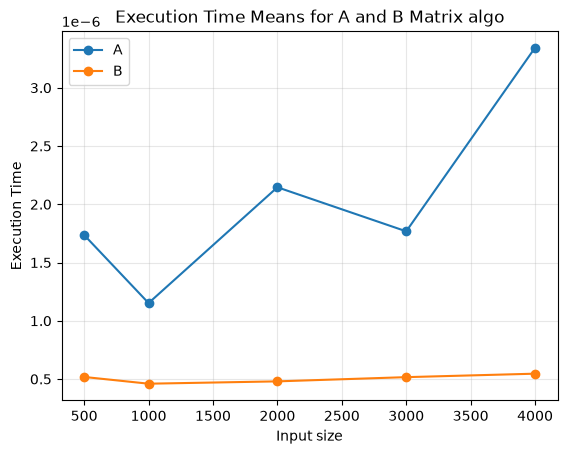

In [22]:
plt.plot(reshaped["size"], reshaped["mean_A"], marker="o", label="A")
plt.plot(reshaped["size"], reshaped["mean_B"], marker="o", label="B")

plt.xlabel("Input size")
plt.ylabel("Execution Time")
plt.title("Execution Time Means for A and B Matrix algo")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

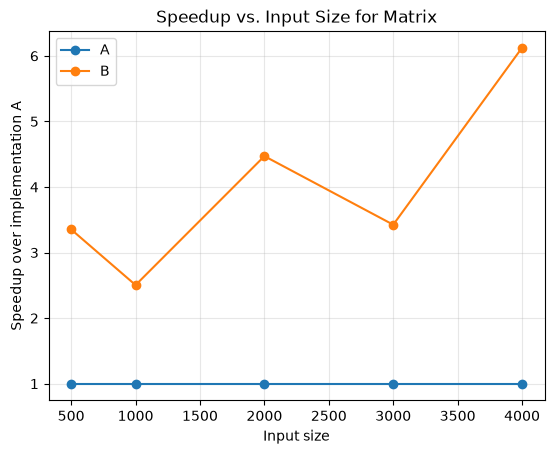

In [20]:
plt.plot(speed_df["size"], speed_df["speedA"], marker="o", label="A")
plt.plot(speed_df["size"], speed_df["speedB"], marker="o", label="B")

plt.xlabel("Input size")
plt.ylabel("Speedup over implementation A")
plt.title("Speedup vs. Input Size for Matrix")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

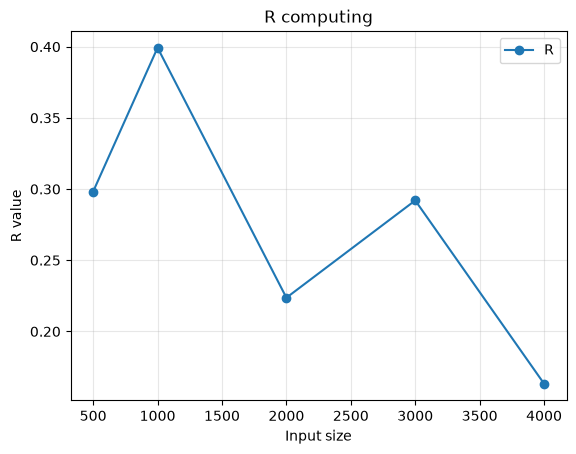

In [23]:
# Calculo de R = T_colunas/T_linhas
reshaped['R'] = reshaped['mean_B'] / reshaped['mean_A']
plt.plot(reshaped["size"], reshaped["R"], marker="o", label="R")

plt.xlabel("Input size")
plt.ylabel("R value")
plt.title("R computing")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()



# Questão 7 – Experimento
R é uma constante de proporção entre o tempo de execucao de sum_A(linhas) e sum_B(colunas) e ele representa para um dado N o quanto que T_colunas muda em relação proporcional a T_linhas, pois pela eq: 

  T_colunas = R T_linhas

ve-se que T_colunas é proporcional a T_linhas por R. dado um T_colunsa fixo e R:

 se 0<R<1, sabe-se que o valor de T_linhas é necessariamente maior que T_linhas, pois um Numero N multiplicado por um valor entre 0 e 1 eh menor que o proprio N

Se R>1, sabe-se que o valor T_linhas é menor que T_colunas, pois um Numero N multiplicado por um valor maior que 1 eh maior que o proprio N

Se R=1, sabe-se que o valor T_linhas é igual a T_colunas, pois um Numero N multiplicado por um valor igual a 1 eh igual ao proprio N

Note que R no experimento é sempre menor que 1, oq contrario ao esperado indica que a execução por colunas é mais rapida que a execução por linhas






# Questão 12

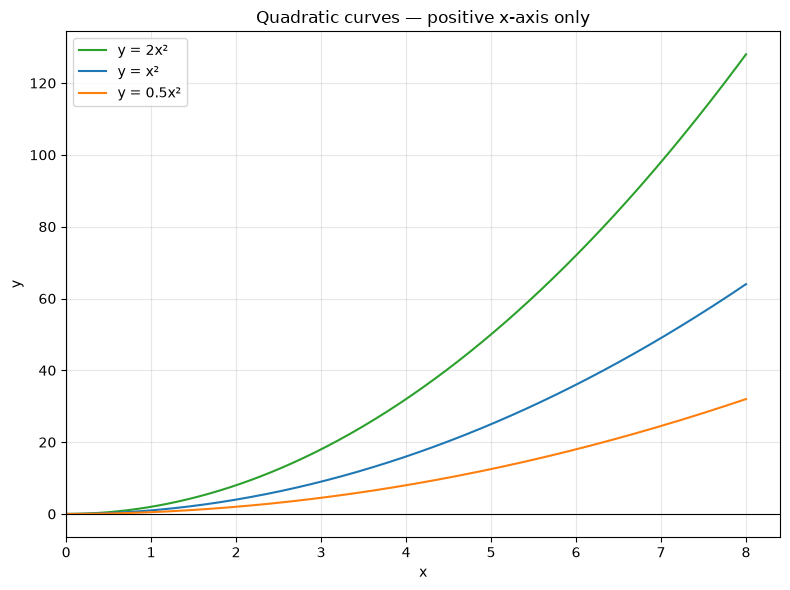

In [29]:
def plot_quadratic(a, b, c, x_max=10, ax=None, label=None, **kwargs):
    """Plot y = ax² + bx + c for x in [0, x_max]."""
    if ax is None:
        ax = plt.gca()
    x = np.linspace(0, x_max, 400)          # <-- starts at 0, so only positive x
    y = a * x**2 + b * x + c
    ax.plot(x, y, label=label or f"y = {a}x² + {b}x + {c}", **kwargs)
    return ax


fig, ax = plt.subplots(figsize=(8, 6))

plot_quadratic( 2,   0.0,  0.0, x_max=8, ax=ax, color="C2", label="y = 2x²")
plot_quadratic( 1.0, 0.0,  0.0, x_max=8, ax=ax, color="C0", label="y = x²")
plot_quadratic( 0.5, 0.0,  0.0, x_max=8, ax=ax, color="C1", label="y = 0.5x²")

# Axes through the origin
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="black", lw=0.8)

ax.set_xlim(left=0)          # hard-lock the visible region to x ≥ 0
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Quadratic curves — positive x-axis only")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# O(N²) indinca uma equçao polinomial de segundo grau do tipo: 
#
# y = ax² + bx + c
#
# Como observado no grafico acima, apesar dos polinomios terem o mesmo grau, a maneira como eles 'abrem' varia drasticamente o valor a. Por essa razao um algoritmo de ordem 2 com 0<a<1 como o caso das linha amarela tem um crescimento temporal muito menor que algoritmos de ordem 2 com a > 1 caso da linha verde.
# isso conside